# Hafta 9 — Renk Uzayları ve Görüntü İşleme
5 soru + 2 haftalık görev. Bütün görüntü işleme algoritmaları C++/OpenCV ile çalışır. Python/JavaScript sadece dosya aktarımı, kamera yakalama ve gösterim içindir.
Hücreleri sırayla çalıştırınız. `image.jpg`, `imagee.jpeg`, `imagii.jpg` dosyalarını yükleyiniz.

In [1]:
!sudo apt-get update -qq
!sudo apt-get install -y libopencv-dev pkg-config

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  at-spi2-common at-spi2-core gsettings-desktop-schemas
  gstreamer1.0-plugins-base libatk-bridge2.0-0t64 libatk1.0-0t64
  libatspi2.0-0t64 libavcodec-dev libavformat-dev libavutil-dev libcdparanoia0
  libcharls2 libdc1394-dev libdouble-conversion3 libevdev2 libexif-dev
  libexif-doc libexif12 libgdcm-dev libgdcm3.0t64 libgl2ps1.4 libglew2.2
  libgphoto2-6t64 libgphoto2-dev libgphoto2-l10n libgphoto2-port12t64
  libgstreamer-plugins-base1.0-0 libgtk-3-0t64 libgtk-3-bin libgtk-3-common
  libgudev-1.0-0 libimath-3-1-29t64 libimath-dev libinput-bin libinput10
  libmd4c0 libmtdev1t64 libopencv-calib3d-dev libopencv-calib3d406t64
  libopencv-contrib-dev libo

## 1. Renk uzayları
| Uzay | Avantaj | Dezavantaj | Kullanım |
|---|---|---|---|
| RGB | Basit, yaygın | Işık değişimine duyarlı | Ekran, kamera |
| HSV | Renk tonu ve parlaklığı ayırır | Düşük doygunlukta H kararsız | Renk tespiti |
| YUV | Parlaklık ve renk farkını ayırır | Dönüşüm gerekir | Video |
| CIE Lab | Algısal renk farkına yakın | Dönüşüm karmaşık | Renk karşılaştırma |
| Gray Scale | Tek kanal, az bellek | Renk kaybolur | Kenar tespiti |
OpenCV BGR sırası kullanır. HSV/YUV/Lab dosyaları kanal kodlarını saklar; BMP/PNG bunları doğal renk olarak yorumlayamaz. Aşağıda ayrı kanallar gösterilir.

In [9]:
%%writefile /content/hafta9_1.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
using namespace cv;
using namespace std;

int main() {
    Mat img = imread("/content/image.jpg", IMREAD_COLOR);

    if (img.empty()) {
        cout << "Goruntu bulunamadi!" << endl;
        return 1;
    }

    Mat hsv, yuv, lab, gray;

    cvtColor(img, hsv, COLOR_BGR2HSV);
    cvtColor(img, yuv, COLOR_BGR2YUV);
    cvtColor(img, lab, COLOR_BGR2Lab);
    cvtColor(img, gray, COLOR_BGR2GRAY);

    imwrite("/content/hafta9_1_RGB.png", img);
    imwrite("/content/hafta9_1_HSV.png", hsv);
    imwrite("/content/hafta9_1_YUV.png", yuv);
    imwrite("/content/hafta9_1_Lab.png", lab);
    imwrite("/content/hafta9_1_Gray.png", gray);

    cout << "Islem tamamlandi!" << endl;

    return 0;
}

Overwriting /content/hafta9_1.cpp


In [10]:
!g++ -std=c++17 -O2 /content/hafta9_1.cpp -o /content/hafta9_1 $(pkg-config --cflags --libs opencv4) && /content/hafta9_1
!ls -lh /content/hafta9_1_*.png

Islem tamamlandi!
-rw-r--r-- 1 root root 15K Nov 17 14:39 /content/hafta9_1_Gray.png
-rw-r--r-- 1 root root 52K Nov 17 14:39 /content/hafta9_1_HSV.png
-rw-r--r-- 1 root root 37K Nov 17 14:39 /content/hafta9_1_Lab.png
-rw-r--r-- 1 root root 44K Nov 17 14:39 /content/hafta9_1_RGB.png
-rw-r--r-- 1 root root 36K Nov 17 14:39 /content/hafta9_1_YUV.png


In [ ]:
!g++ -std=c++17 -O2 /content/hafta9_1.cpp -o /content/hafta9_1 $(pkg-config --cflags --libs opencv4) && /content/hafta9_1

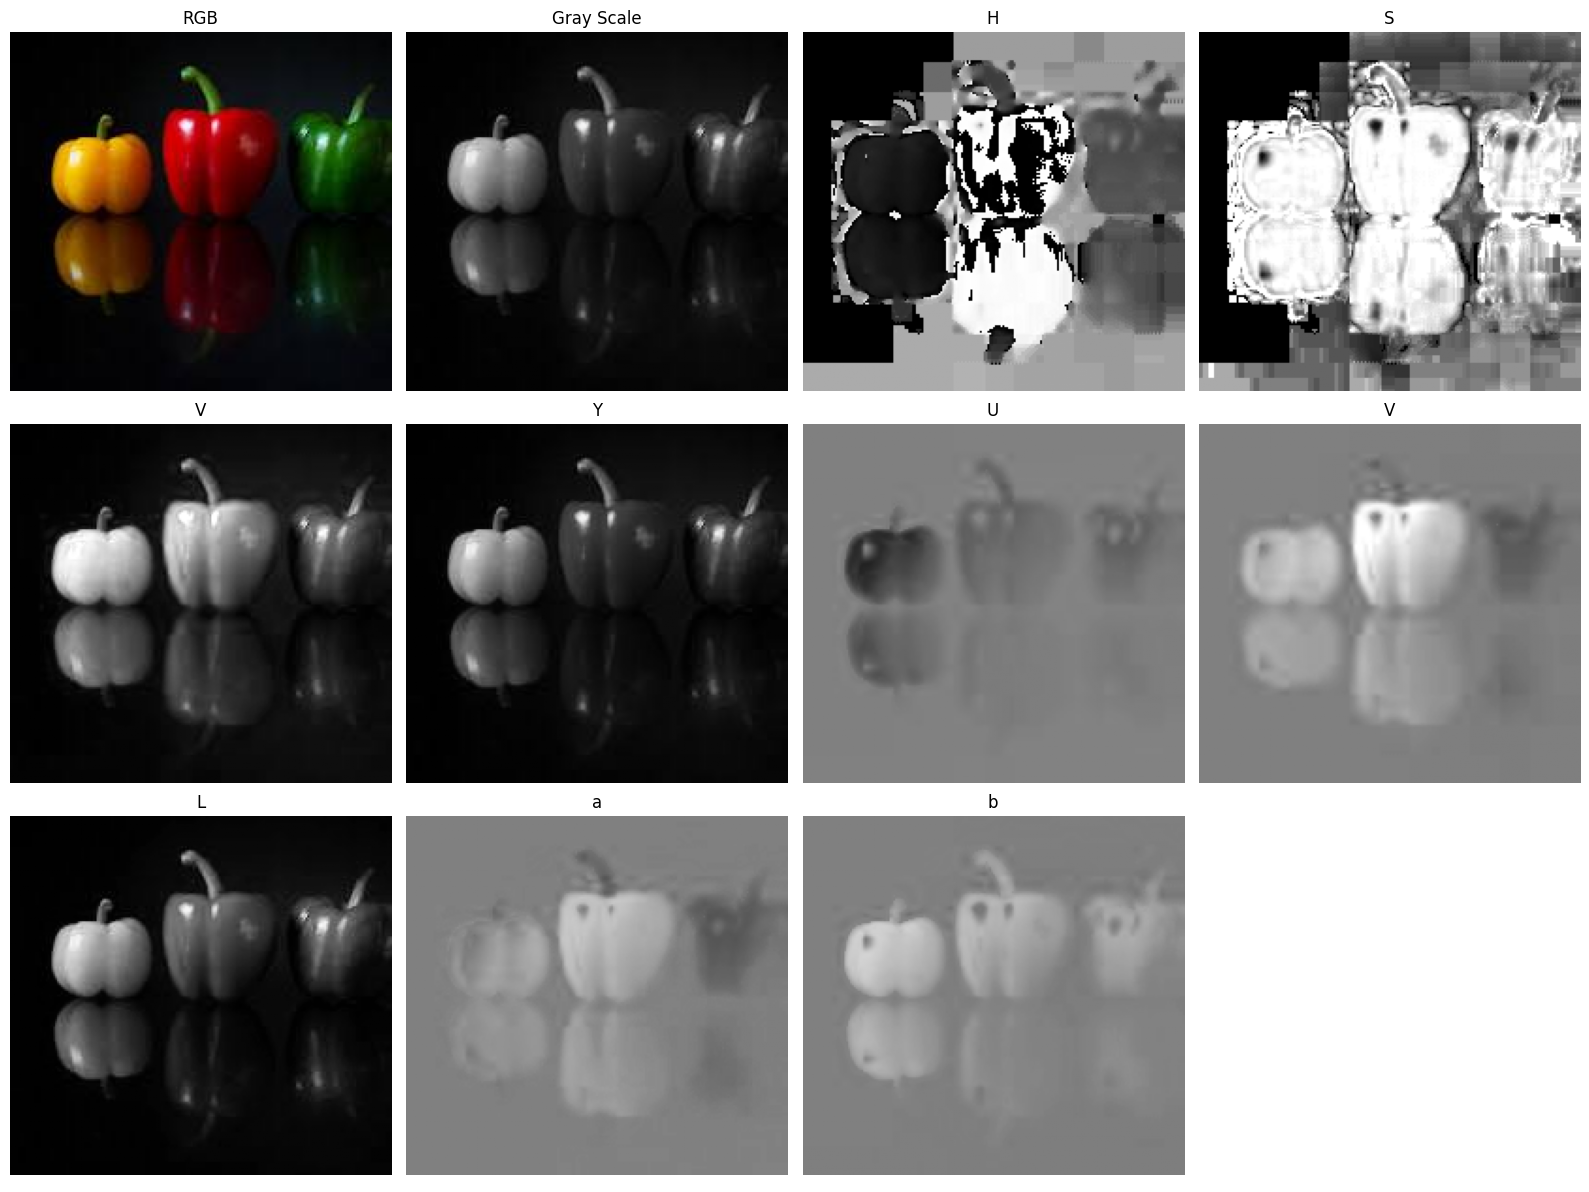

In [11]:
import cv2
import matplotlib.pyplot as plt

fig, ax = plt.subplots(3, 4, figsize=(16, 12))

images = [
    ("RGB", "RGB", None),
    ("Gray", "Gray Scale", None),
    ("HSV", "H", 0),
    ("HSV", "S", 1),
    ("HSV", "V", 2),
    ("YUV", "Y", 0),
    ("YUV", "U", 1),
    ("YUV", "V", 2),
    ("Lab", "L", 0),
    ("Lab", "a", 1),
    ("Lab", "b", 2)
]

for i, (nom, titre, canal) in enumerate(images):
    img = cv2.imread("/content/hafta9_1_" + nom + ".png", -1)

    if img is not None:
        if canal is not None:
            ax.flat[i].imshow(img[:,:,canal], cmap="gray",
                              vmin=0, vmax=179 if titre=="H" else 255)
        elif nom == "Gray":
            ax.flat[i].imshow(img, cmap="gray", vmin=0, vmax=255)
        else:
            ax.flat[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))

    ax.flat[i].set_title(titre)

for a in ax.flat:
    a.axis("off")

plt.tight_layout()
plt.savefig("/content/hafta9_1_sonuclari.png", dpi=150)
plt.show()

Orijinal RGB görüntü, HSV, YUV, CIE Lab ve Gray Scale renk uzaylarına dönüştürülmüştür. Her renk uzayının kanalları ayrı ayrı incelenmiştir. HSV renk tonu ve doygunluk bilgilerini, YUV parlaklık ve renk farkı bilgilerini, CIE Lab ise açıklık ve renk bileşenlerini göstermektedir. Gray Scale görüntü yalnızca gri seviye bilgisi içermektedir.

## 2. 1000×1000 BMP ve gri tonlama
JPG kaynak önce gerçek BMP olarak kaydedilir ve tekrar açılır. Ham veri: 3.000.000 ve 1.000.000 bayt; gerçek dosya boyutları başlık/palet nedeniyle farklı olabilir.

In [18]:
%%writefile /content/hafta9_2.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <filesystem>
using namespace cv;
using namespace std;
namespace fs = std::filesystem;

int main() {
    Mat img = imread("/content/image.jpg", IMREAD_COLOR);

    if (img.empty()) {
        cout << "Goruntu bulunamadi!" << endl;
        return 1;
    }

    resize(img, img, Size(1000, 1000));

    imwrite("/content/hafta9_2_RGB.bmp", img);

    Mat renkli = imread("/content/hafta9_2_RGB.bmp");

    Mat gray;
    cvtColor(renkli, gray, COLOR_BGR2GRAY);

    imwrite("/content/hafta9_2_Gray.bmp", gray);

    cout << "Cozunurluk: " << renkli.cols << "x" << renkli.rows << endl;

    cout << "Renkli kanal: " << renkli.channels() << endl;
    cout << "Gri kanal: " << gray.channels() << endl;

    cout << "Renkli BMP: "
         << fs::file_size("/content/hafta9_2_RGB.bmp")
         << " byte" << endl;

    cout << "Gri BMP: "
         << fs::file_size("/content/hafta9_2_Gray.bmp")
         << " byte" << endl;

    return 0;
}

Overwriting /content/hafta9_2.cpp


In [21]:
!g++ -std=c++17 -O2 /content/hafta9_2.cpp -o /content/hafta9_2 $(pkg-config --cflags --libs opencv4) && /content/hafta9_2

Cozunurluk: 1000x1000
Renkli kanal: 3
Gri kanal: 1
Renkli BMP: 3000054 byte
Gri BMP: 1001078 byte


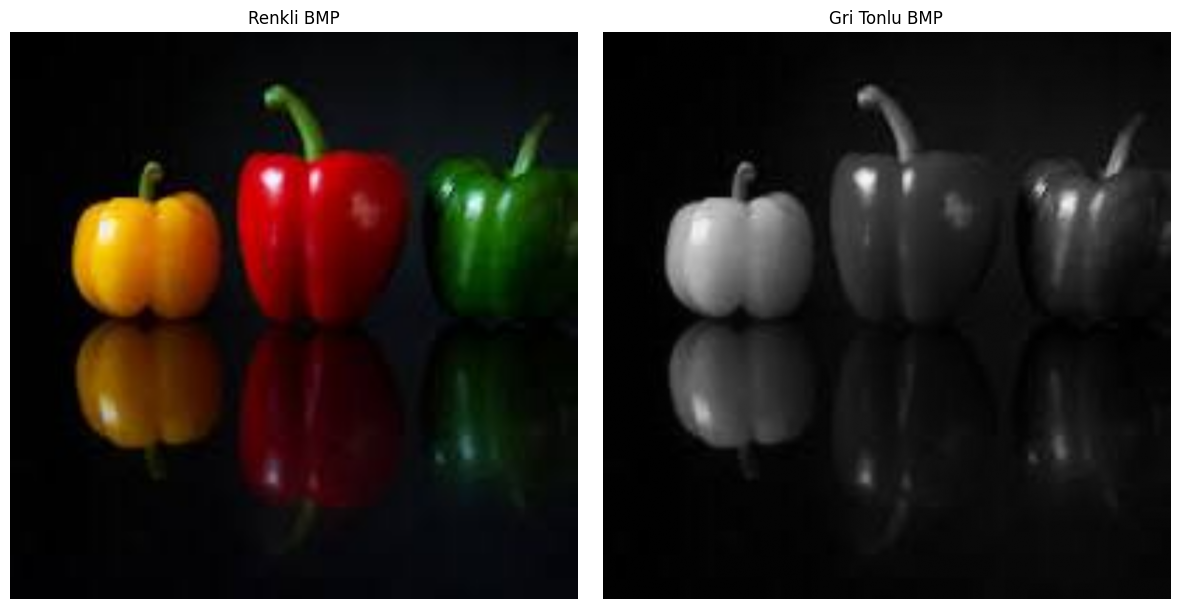

In [22]:
import cv2
import matplotlib.pyplot as plt

renkli = cv2.imread("/content/hafta9_2_RGB.bmp")
gray = cv2.imread("/content/hafta9_2_Gray.bmp", 0)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(renkli, cv2.COLOR_BGR2RGB))
plt.title("Renkli BMP")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
plt.title("Gri Tonlu BMP")
plt.axis("off")

plt.tight_layout()
plt.show()

## 3. 8K BMP ve süre ölçümü
16×16 rastgele renkli bloklar; 7680×4320, 3 kanal. Yalnızca piksel döngüsü kronometreye dahildir. Sonuç daha koyudur.

In [23]:
%%writefile /content/hafta9_3.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <chrono>
#include <iomanip>
using namespace cv;
using namespace std;
using namespace std::chrono;
int main() {
    Mat resim(4320,7680,CV_8UC3);
    RNG rng(12345);
    for (int y=0; y<resim.rows; y+=16) {
        for (int x=0; x<resim.cols; x+=16) {
            Scalar renk(rng.uniform(0,256),rng.uniform(0,256),rng.uniform(0,256));
            resim(Rect(x,y,16,16)).setTo(renk);
        }
    }
    if (!imwrite("/content/hafta9_3_RGB.bmp",resim)) return 1;
    resim.release();
    Mat img=imread("/content/hafta9_3_RGB.bmp");
    if (img.empty()) return 1;
    auto baslangic=steady_clock::now();
    for (int y=0; y<img.rows; y++) {
        Vec3b* p=img.ptr<Vec3b>(y);
        for (int x=0; x<img.cols; x++) {
            for (int c=0; c<3; c++) p[x][c]/=2;
        }
    }
    auto bitis=steady_clock::now();
    double sure=duration<double,milli>(bitis-baslangic).count();
    if (!imwrite("/content/hafta9_3_Sonuc.bmp",img)) return 1;
    cout << fixed << setprecision(6) << "Islem suresi: " << sure << " ms\n";
    return 0;
}


Writing /content/hafta9_3.cpp


In [24]:
!g++ -std=c++17 -O2 /content/hafta9_3.cpp -o /content/hafta9_3 $(pkg-config --cflags --libs opencv4) && /content/hafta9_3

Islem suresi: 36.884009 ms


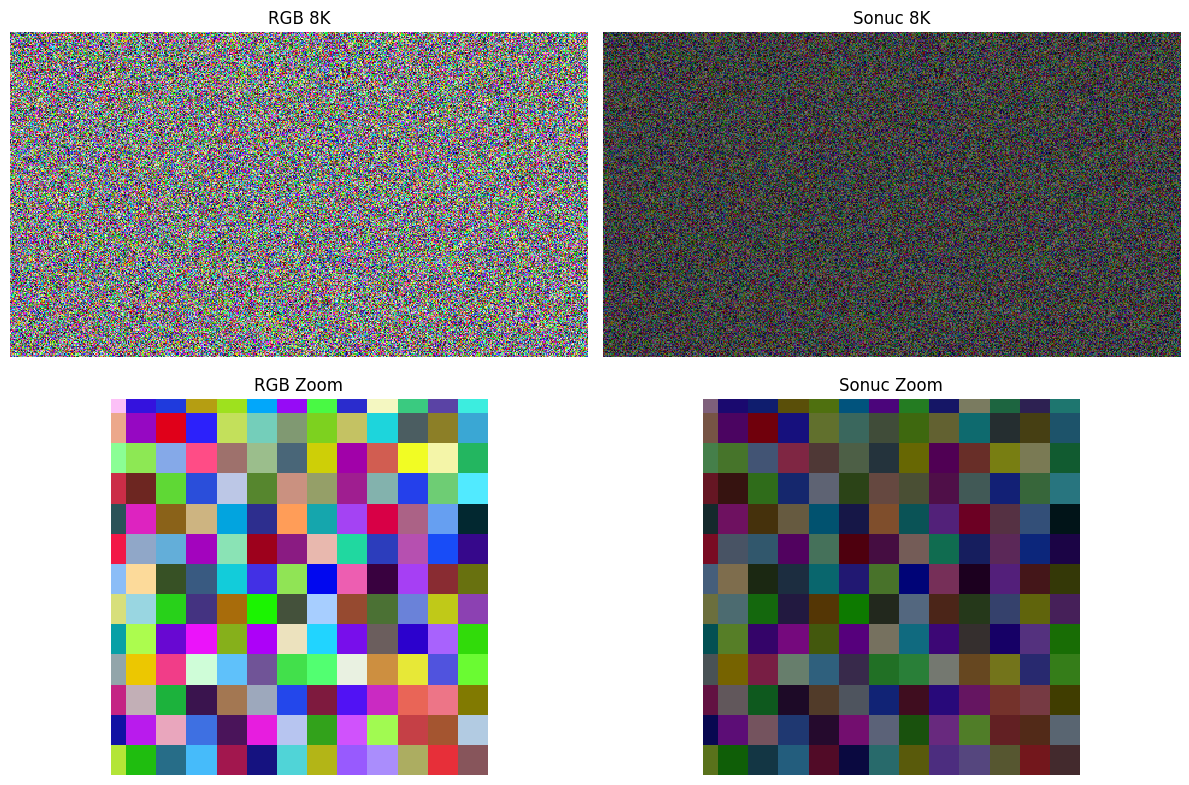

In [25]:
fig,axes=plt.subplots(2,2,figsize=(12,8))
for i,name in enumerate(['RGB','Sonuc']):
    img=cv2.imread('/content/hafta9_3_'+name+'.bmp')
    if img is None: print('Missing:',name); continue
    axes[0,i].imshow(img[::8,::8,::-1],interpolation='nearest'); axes[0,i].set_title(name+' 8K')
    axes[1,i].imshow(img[1000:1200,1000:1200,::-1],interpolation='nearest'); axes[1,i].set_title(name+' Zoom')
    for ax in axes[:,i]: ax.axis('off')
plt.tight_layout(); plt.show()

In [32]:
%%writefile /content/hafta9_4.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <cmath>
#include <algorithm>

using namespace cv;
using namespace std;

int main() {
    Mat img = imread("/content/image.jpg");

    if (img.empty()) {
        cout << "Goruntu bulunamadi!" << endl;
        return 1;
    }

    // RGB BMP
    imwrite("/content/hafta9_4_RGB.bmp", img);
    img = imread("/content/hafta9_4_RGB.bmp");

    Mat hsv, yuv, lab;
    Mat hsi(img.size(), CV_8UC3);

    // RGB -> HSV
    cvtColor(img, hsv, COLOR_BGR2HSV);

    // RGB -> YUV
    cvtColor(img, yuv, COLOR_BGR2YUV);

    // RGB -> CIE Lab
    cvtColor(img, lab, COLOR_BGR2Lab);

    // RGB -> HSI
    for (int y = 0; y < img.rows; y++) {
        for (int x = 0; x < img.cols; x++) {

            Vec3b p = img.at<Vec3b>(y, x);

            double B = p[0] / 255.0;
            double G = p[1] / 255.0;
            double R = p[2] / 255.0;

            double I = (R + G + B) / 3.0;
            double S = 0;
            double H = 0;

            if (I > 0)
                S = 1 - min({R, G, B}) / I;

            if (S > 1e-9) {
                H = atan2(sqrt(3.0)*(G-B), 2*R-G-B);

                if (H < 0)
                    H += 2 * CV_PI;
            }

            hsi.at<Vec3b>(y, x) = Vec3b(
                saturate_cast<uchar>(H * 255 / (2*CV_PI)),
                saturate_cast<uchar>(S * 255),
                saturate_cast<uchar>(I * 255)
            );
        }
    }

    // BMP formatinda kaydetme
    imwrite("/content/hafta9_4_HSV.bmp", hsv);
    imwrite("/content/hafta9_4_HSI.bmp", hsi);
    imwrite("/content/hafta9_4_YUV.bmp", yuv);
    imwrite("/content/hafta9_4_Lab.bmp", lab);

    cout << "Donusumler tamamlandi!" << endl;

    return 0;
}

Overwriting /content/hafta9_4.cpp


In [36]:
!g++ -std=c++17 -O2 /content/hafta9_4.cpp -o /content/hafta9_4 $(pkg-config --cflags --libs opencv4) && /content/hafta9_4

Donusumler tamamlandi!


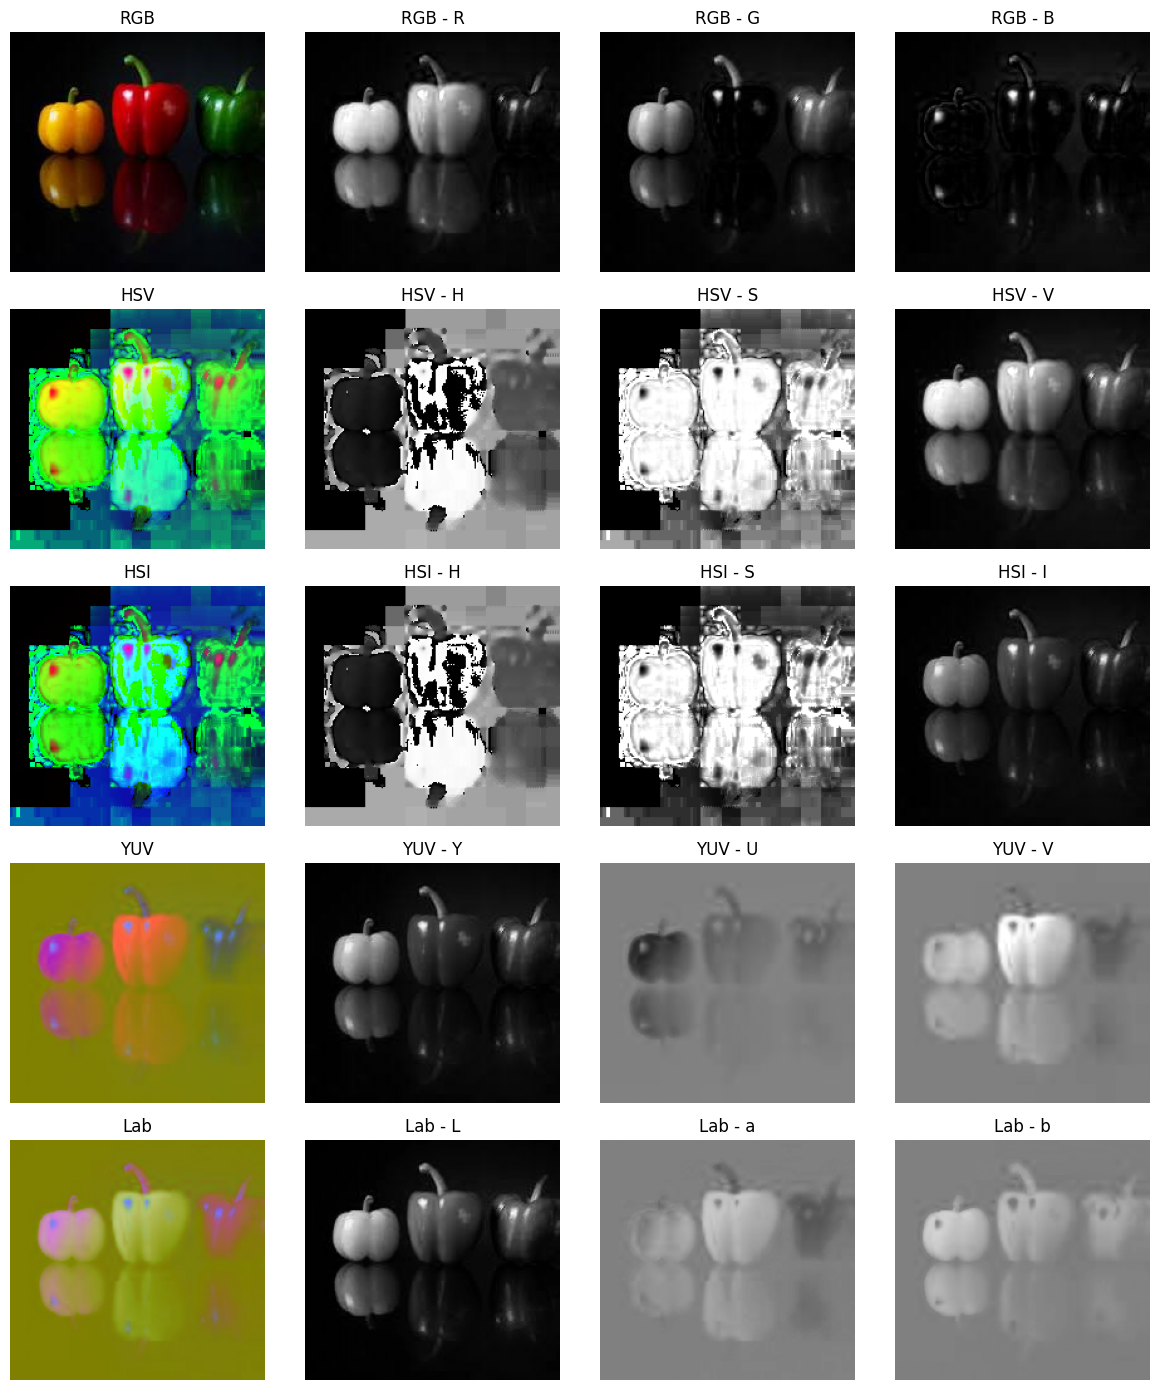

In [65]:
import cv2
import matplotlib.pyplot as plt

spaces = [
    ("RGB", ["R", "G", "B"]),
    ("HSV", ["H", "S", "V"]),
    ("HSI", ["H", "S", "I"]),
    ("YUV", ["Y", "U", "V"]),
    ("Lab", ["L", "a", "b"])
]

fig, axes = plt.subplots(5, 4, figsize=(12, 14))

for i, (name, labels) in enumerate(spaces):

    img = cv2.imread("/content/hafta9_4_" + name + ".bmp")

    if img is None:
        print("Missing:", name)
        continue

    axes[i,0].imshow(img[:,:,::-1])
    axes[i,0].set_title(name)

    for j in range(3):

        index = 2-j if name == "RGB" else j
        maximum = 179 if name == "HSV" and j == 0 else 255

        axes[i,j+1].imshow(
            img[:,:,index],
            cmap="gray",
            vmin=0,
            vmax=maximum
        )

        axes[i,j+1].set_title(name + " - " + labels[j])

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 5. Ten rengi tespiti
RGB, HSV ve YCbCr ile ten olmayan bölgeler kırmızı yapılır. Eşikler örnektir; ışığa ve cilt tonlarına göre yanlış tespit mümkündür.

In [38]:
%%writefile /content/hafta9_5.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <algorithm>
#include <cmath>
using namespace cv;
using namespace std;
void tespit(string dosya,string isim) {
    Mat img=imread("/content/"+dosya);
    if(img.empty()) {cerr<<dosya<<" bulunamadi\n";return;}
    Mat hsv,ycc;
    cvtColor(img,hsv,COLOR_BGR2HSV);
    cvtColor(img,ycc,COLOR_BGR2YCrCb);
    Mat a=img.clone(),b=img.clone(),c=img.clone();
    for(int y=0;y<img.rows;y++) {
        for(int x=0;x<img.cols;x++) {
            Vec3b p=img.at<Vec3b>(y,x),h=hsv.at<Vec3b>(y,x),z=ycc.at<Vec3b>(y,x);
            int B=p[0],G=p[1],R=p[2];
            bool rgb=R>95 && G>40 && B>20 && max({R,G,B})-min({R,G,B})>15 && abs(R-G)>15 && R>G && R>B;
            bool hs=h[0]<=25 && h[1]>=35 && h[1]<=200 && h[2]>=50;
            bool yc=z[1]>=133 && z[1]<=173 && z[2]>=77 && z[2]<=127;
            Vec3b kirmizi(0,0,255);
            if(!rgb) a.at<Vec3b>(y,x)=kirmizi;
            if(!hs) b.at<Vec3b>(y,x)=kirmizi;
            if(!yc) c.at<Vec3b>(y,x)=kirmizi;
        }
    }
    imwrite("/content/hafta9_5_"+isim+"_RGB.png",a);
    imwrite("/content/hafta9_5_"+isim+"_HSV.png",b);
    imwrite("/content/hafta9_5_"+isim+"_YCbCr.png",c);
}
int main(){tespit("imagee.jpeg","imagee");tespit("imagii.jpg","imagii");return 0;}


Overwriting /content/hafta9_5.cpp


In [40]:
!g++ -std=c++17 -O2 /content/hafta9_5.cpp -o /content/hafta9_5 $(pkg-config --cflags --libs opencv4) && /content/hafta9_5

[ WARN:0@0.175] global ./modules/imgcodecs/src/loadsave.cpp (239) findDecoder imread_('/content/imagii.jpg'): can't open/read file: check file path/integrity
imagii.jpg bulunamadi


In [41]:
!ls /content/

hafta9_1		hafta9_3	    hafta9_5.cpp
hafta9_1.cpp		hafta9_3.cpp	    hafta9_5_imagee_HSV.png
hafta9_1_Gray.png	hafta9_3_RGB.bmp    hafta9_5_imagee_RGB.png
hafta9_1_HSV.png	hafta9_3_Sonuc.bmp  hafta9_5_imagee_YCbCr.png
hafta9_1_Lab.png	hafta9_4	    imagee.jpeg
hafta9_1_RGB.png	hafta9_4.cpp	    image.jpg
hafta9_1_sonuclari.png	hafta9_4_HSI.bmp    sample_data
hafta9_1_YUV.png	hafta9_4_HSV.bmp    trafik1.jpg
hafta9_2		hafta9_4_Lab.bmp    trafik2.jpg
hafta9_2.cpp		hafta9_4_RGB.bmp    trafik3.jpg
hafta9_2_Gray.bmp	hafta9_4_YUV.bmp    video.mp4
hafta9_2_RGB.bmp	hafta9_5


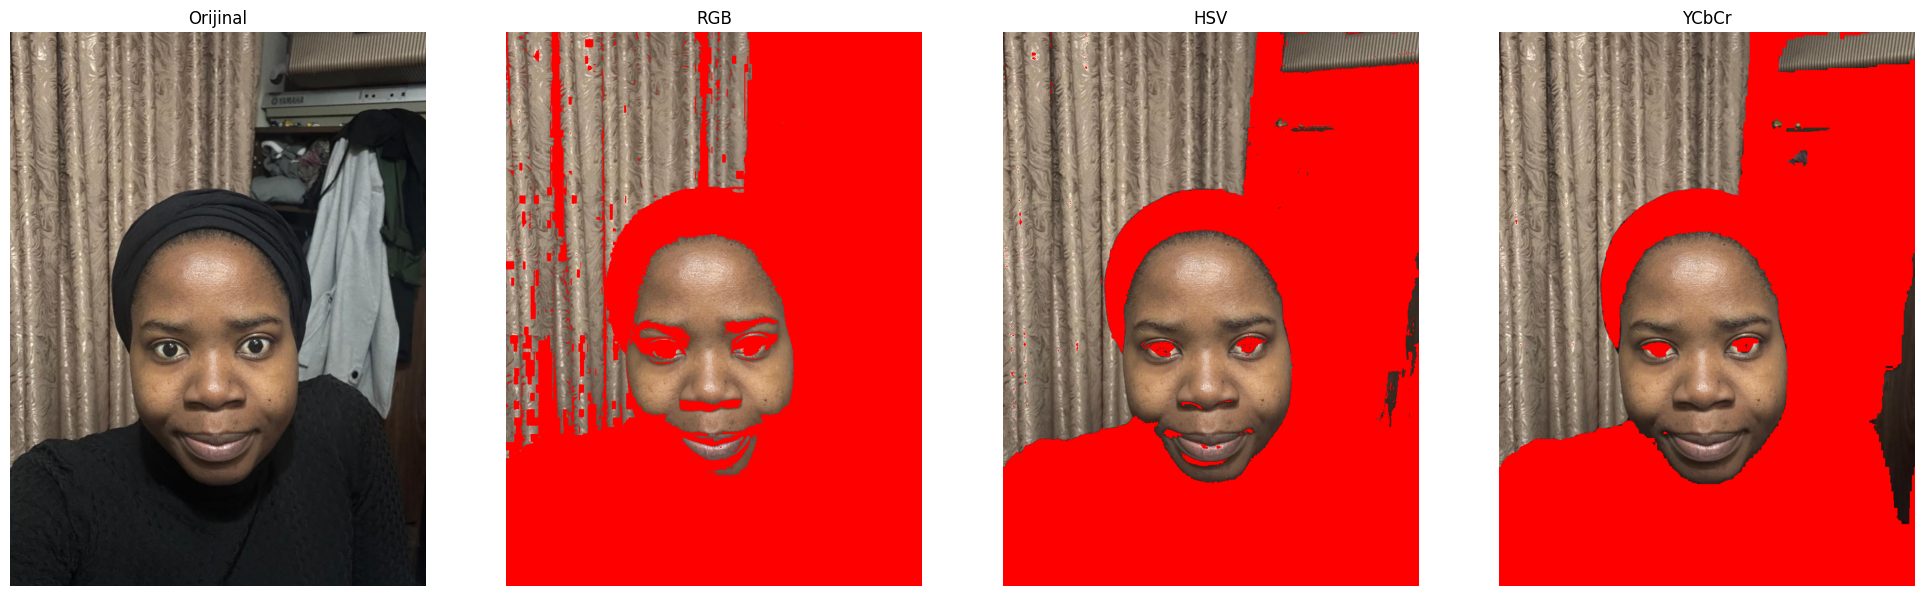

In [42]:
import cv2
import matplotlib.pyplot as plt

paths = [
    "/content/imagee.jpeg",
    "/content/hafta9_5_imagee_RGB.png",
    "/content/hafta9_5_imagee_HSV.png",
    "/content/hafta9_5_imagee_YCbCr.png"
]

titles = ["Orijinal", "RGB", "HSV", "YCbCr"]

fig, axes = plt.subplots(1, 4, figsize=(20, 6))

for ax, path, title in zip(axes, paths, titles):
    img = cv2.imread(path)

    if img is not None:
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        print("Missing:", path)

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
for name,ext in [('imagee','.jpeg'),('imagii','.jpg')]:
    show(['/content/'+name+ext]+['/content/hafta9_5_'+name+'_'+m+'.png' for m in ['RGB','HSV','YCbCr']],['Orijinal','RGB','HSV','YCbCr'])

## Haftalık Görev 1 — Kamera, hareket ve ROI
Colab'da yerel kamera doğrudan C++ sunucusuna bağlı değildir. Aşağıdaki hücre tarayıcıdan 6 saniyelik video kaydeder (kamera izni gerekir). C++ art arda gelen kareleri işler; hareket yeterliyse ROI içinde ten piksellerini yeşil boyar. Dış bölgeler değiştirilmez. Yerel bilgisayarda argümansız program `VideoCapture(0)` ile kamerayı açar (ESC çıkış).

In [46]:
%%writefile /content/hafta9_gorev1.cpp
#include <opencv2/opencv.hpp>
#include <iostream>

using namespace cv;
using namespace std;

int main() {

    VideoCapture cap("/content/video.mp4");

    if (!cap.isOpened()) {
        cout << "Video acilamadi!" << endl;
        return 1;
    }

    int width = cap.get(CAP_PROP_FRAME_WIDTH);
    int height = cap.get(CAP_PROP_FRAME_HEIGHT);
    double fps = cap.get(CAP_PROP_FPS);

    if (fps <= 0) fps = 25;

    VideoWriter output(
        "/content/hafta9_gorev1.avi",
        VideoWriter::fourcc('M','J','P','G'),
        fps, Size(width, height)
    );

    if (!output.isOpened()) {
        cout << "Video kaydedilemiyor!" << endl;
        return 1;
    }

    Mat frame, previous, gray, diff, motion;
    Mat ycbcr, skin;

    while (cap.read(frame)) {

        cvtColor(frame, gray, COLOR_BGR2GRAY);
        GaussianBlur(gray, gray, Size(5,5), 0);

        if (!previous.empty()) {

            // Hareket tespiti
            absdiff(previous, gray, diff);
            threshold(diff, motion, 25, 255, THRESH_BINARY);

            erode(motion, motion, Mat());
            dilate(motion, motion, Mat(), Point(-1,-1), 3);

            if (countNonZero(motion) > 500) {

                vector<Point> points;
                findNonZero(motion, points);

                // ROI belirleme
                Rect roi = boundingRect(points);

                Mat region = frame(roi);

                // Ten rengi tespiti
                cvtColor(region, ycbcr, COLOR_BGR2YCrCb);

                inRange(ycbcr,
                        Scalar(0,133,77),
                        Scalar(255,173,127),
                        skin);

                // Ten rengini yesil yap
                region.setTo(Scalar(0,255,0), skin);

                // ROI cercevesi
                rectangle(frame, roi, Scalar(255,0,0), 2);

                putText(frame, "Hareket - ROI",
                        Point(20,40),
                        FONT_HERSHEY_SIMPLEX,
                        1, Scalar(0,255,0), 2);
            }
        }

        gray.copyTo(previous);
        output.write(frame);
    }

    cap.release();
    output.release();

    cout << "Video islemi tamamlandi!" << endl;

    return 0;
}

Overwriting /content/hafta9_gorev1.cpp


In [47]:
!g++ -std=c++17 -O2 /content/hafta9_gorev1.cpp -o /content/hafta9_gorev1 $(pkg-config --cflags --libs opencv4) && /content/hafta9_gorev1 /content/webcam.webm

Video islemi tamamlandi!


In [50]:
!ffmpeg -y -i /content/hafta9_gorev1.avi -c:v libx264 -pix_fmt yuv420p /content/hafta9_gorev1_sonuc.mp4

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

In [51]:
from IPython.display import Video

Video("/content/hafta9_gorev1_sonuc.mp4", embed=True)

In [52]:
from google.colab import files

files.download("/content/hafta9_gorev1_sonuc.mp4")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Haftalık Görev 2 — Kırmızı çemberli trafik işaretleri
[Veri seti](https://www.kaggle.com/datasets/tabishalam0/traffic-signs-dataset-germany-uk-usa). HSV ve YCrCb kırmızı maskeleri birleştirilir; Hough çemberleri bulunur ve çevrede kırmızı piksel desteği kontrol edilir. Bu yöntem bir aday tespitidir; doğruluk ölçümü için etiketli test gerekir. Veri seti indirilemezse Kaggle ZIP dosyasını Colab'a yükleyip `/content/traffic_signs` altına çıkarınız ve `dataset_path` değişkenini bu dizine ayarlayınız.

In [53]:
import kagglehub
dataset_path = kagglehub.dataset_download("tabishalam0/traffic-signs-dataset-germany-uk-usa")
print(dataset_path)

Using Colab cache for faster access to the 'traffic-signs-dataset-germany-uk-usa' dataset.
/kaggle/input/traffic-signs-dataset-germany-uk-usa


In [60]:
%%writefile /content/hafta9_gorev2.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <vector>
#include <string>

using namespace cv;
using namespace std;

int main() {

    for (int i = 1; i <= 3; i++) {

        string name = "trafik" + to_string(i);

        Mat img = imread("/content/" + name + ".jpg");

        if (img.empty()) {
            cout << name << " bulunamadi!" << endl;
            continue;
        }

        Mat hsv, mask1, mask2, maskHSV;
        Mat maskRGB, mask, gray;

        // HSV renk uzayi
        cvtColor(img, hsv, COLOR_BGR2HSV);

        // Kirmizi renk tespiti
        inRange(hsv, Scalar(0, 70, 50),
                     Scalar(10, 255, 255), mask1);

        inRange(hsv, Scalar(170, 70, 50),
                     Scalar(179, 255, 255), mask2);

        bitwise_or(mask1, mask2, maskHSV);

        // RGB renk uzayi
        maskRGB = Mat::zeros(img.size(), CV_8UC1);

        for (int y = 0; y < img.rows; y++) {
            for (int x = 0; x < img.cols; x++) {

                Vec3b p = img.at<Vec3b>(y,x);

                int B = p[0];
                int G = p[1];
                int R = p[2];

                if (R > 80 && R > 1.4*G && R > 1.4*B)
                    maskRGB.at<uchar>(y,x) = 255;
            }
        }

        // Maskeleri birlestirme
        bitwise_and(maskHSV, maskRGB, mask);

        morphologyEx(mask, mask, MORPH_CLOSE,
                     getStructuringElement(MORPH_ELLIPSE,
                                           Size(5,5)));

        GaussianBlur(mask, gray, Size(9,9), 2);

        // Hough algoritmasi
        vector<Vec3f> circles;

        HoughCircles(gray, circles, HOUGH_GRADIENT,
                     1, 30, 100, 20, 10, 0);

        Mat result = img.clone();

        for (Vec3f c : circles) {

            Point center(cvRound(c[0]), cvRound(c[1]));
            int radius = cvRound(c[2]);

            circle(result, center, radius,
                   Scalar(0,255,0), 3);

            circle(result, center, 3,
                   Scalar(255,0,0), -1);
        }

        imwrite("/content/" + name + "_HSV.png", maskHSV);
        imwrite("/content/" + name + "_RGB.png", maskRGB);
        imwrite("/content/" + name + "_tespit.png", result);

        cout << name << ": " << circles.size()
             << " cember tespit edildi." << endl;
    }

    return 0;
}

Overwriting /content/hafta9_gorev2.cpp


In [61]:
!g++ -std=c++17 -O2 /content/hafta9_gorev2.cpp -o /content/hafta9_gorev2 $(pkg-config --cflags --libs opencv4) && /content/hafta9_gorev2

trafik1: 30 cember tespit edildi.
trafik2: 39 cember tespit edildi.
trafik3: 10 cember tespit edildi.


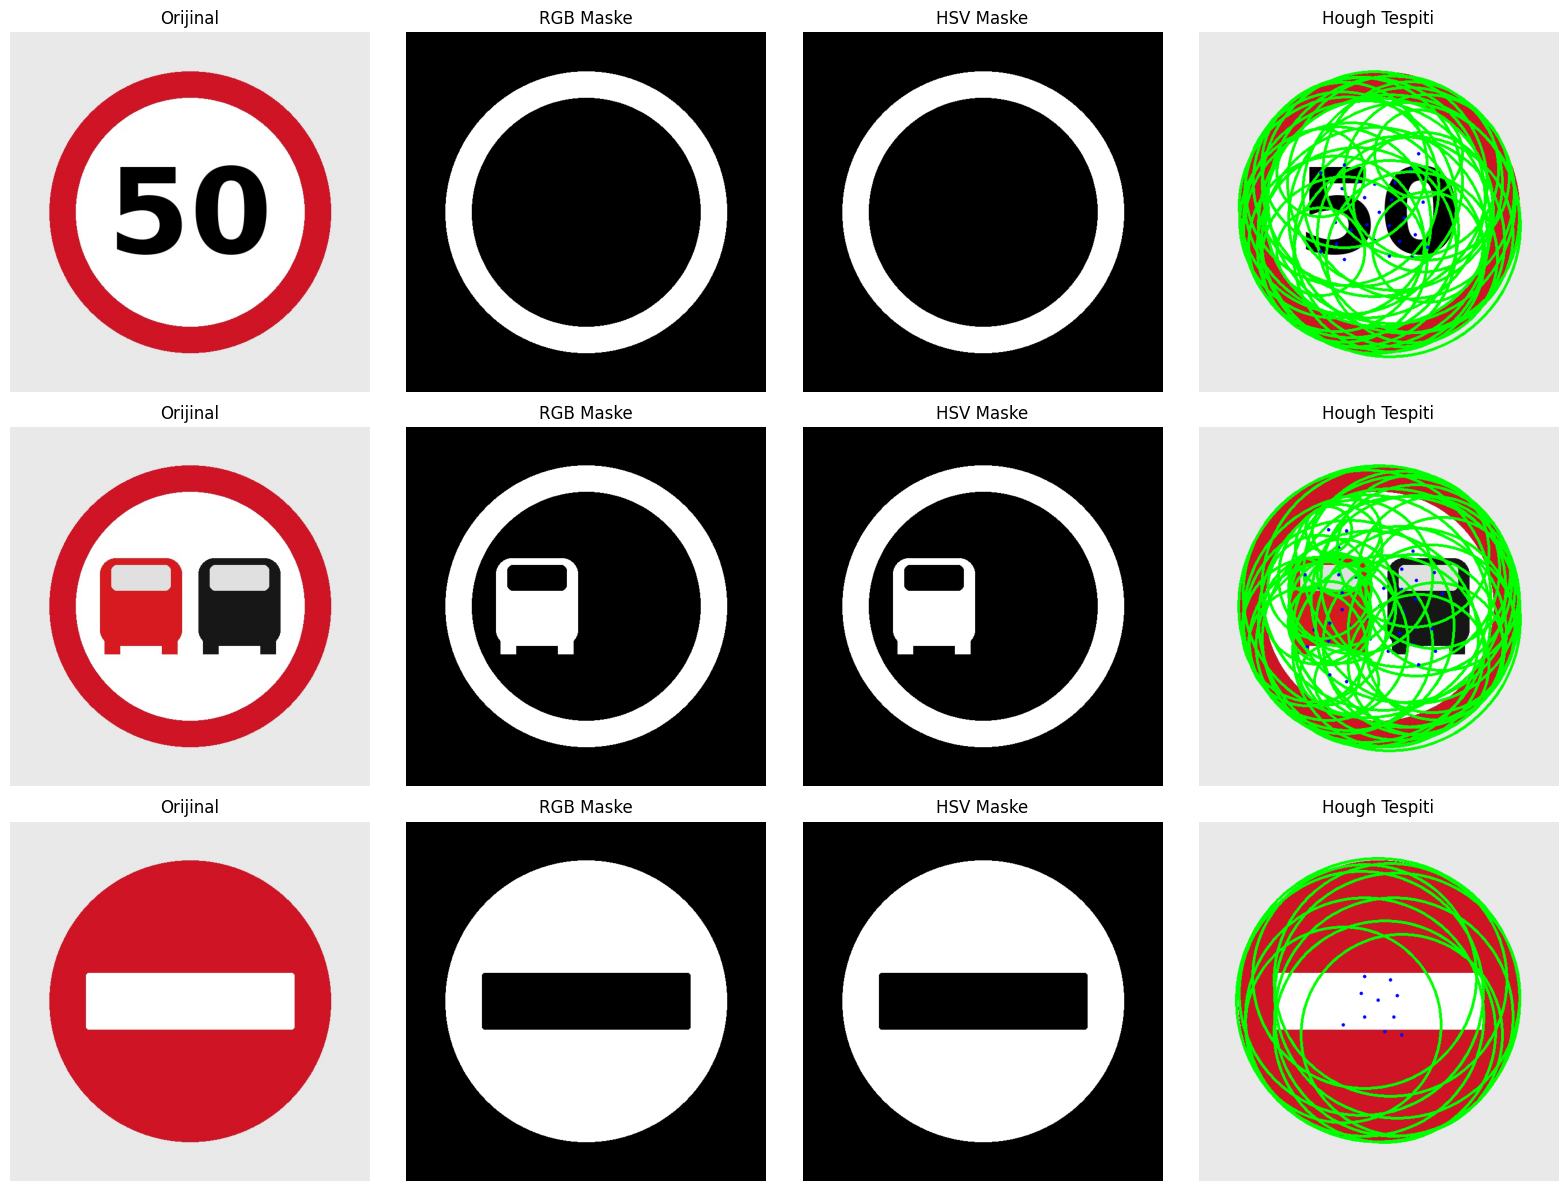

In [62]:
import cv2
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 4, figsize=(16, 12))

for i in range(3):

    name = "/content/trafik" + str(i+1)

    paths = [
        name + ".jpg",
        name + "_RGB.png",
        name + "_HSV.png",
        name + "_tespit.png"
    ]

    titles = ["Orijinal", "RGB Maske",
              "HSV Maske", "Hough Tespiti"]

    for j in range(4):

        img = cv2.imread(paths[j])

        if img is not None:
            axes[i,j].imshow(
                cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            )
        else:
            print("Missing:", paths[j])

        axes[i,j].set_title(titles[j])
        axes[i,j].axis("off")

plt.tight_layout()
plt.show()